# Respiratory infection in Indonesian children: grouped prediction and adjusted association

A cohort of 275 preschool children was examined on up to six consecutive
quarters for respiratory infection, with xerophthalmia (vitamin A
deficiency) recorded at every exam — the study of
{cite:t}`sommer1983increased`, analysed by {cite:t}`zegerkarim1991generalized`
and {cite:t}`diggle2002analysis` among others. The case first uses `autospec`, the library's automatic specification search, to
choose a model for infection in a new child, scoring it on folds that hold whole
children out. It then estimates the adjusted
association between xerophthalmia and infection with a separate causal
specification. That estimate requires assumptions about exposure timing and
unmeasured confounding that prediction alone cannot supply.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | a starting specification measured on folds that respect the cohort design, and the boundary between prediction and the effect question |
| **Observed response** | `infection`, presence of respiratory infection at one exam (0/1) |
| **Estimand** | the held-out risk of candidate specifications; the extension estimates the adjusted risk difference of xerophthalmia |
| **Units** | risk on the probability scale; the risk difference as a difference in infection probability (0.054 is 5.4 percentage points) |
| **Sampling unit** | one child at one quarterly exam; 1200 rows on 275 children |
| **Dependence** | repeated exams within a child share more than the columns record |
| **Split / resampling unit** | the child, held out whole by the detected grouped folds; random rows, in the comparison that shows what the grouping buys |
| **Tuning** | the specification's step count, chosen by cross-validation on the same grouped folds that score candidate shapes |
| **Uncertainty** | cross-validated risk on fixed folds; the extension's influence-function interval |
| **Claim type** | predictive for the specification; the extension's estimate is causal under stated assumptions |
:::

In [1]:
import altair as alt
import polars as pl

import mboostrs as mb
from mboostrs.autospec import autospec
from mboostrs.datasets import resp_inf

kids = resp_inf()

rec0 = autospec(kids, "infection")
print(rec0.report())


autospec: infection ~ bbs(log(child), df=4.0) + bbs(age, df=4.0) + bbs(age_first, df=4.0) + bols(xero) + brandom(cosine, df=4.0) + brandom(sine, df=4.0) + bols(female) + bbs(height, df=4.0) + bols(stunted) + bbs(round, df=4.0) + bols(season)

response: Binomial (inferred)

data hygiene (no fit -- scans only)
  child: sample skewness 14.3, range 121013 to 1.72511e+06 -- fitted as bbs(log(child)): on the raw scale an even knot grid puts most of the spline over a few extreme rows, and a cross-validation fold that holds them out extends the curve across the empty range, so one fold can decide mstop
  resp: one value (1) in 1200 rows -- no learner is produced for it: a term on a constant fits the intercept twice
  xero: 2 distinct values (0, 1) in a float column -- read as groups, not as a measured quantity: a spline would interpolate between labels. Declare measurements="xero" if the values are ordered quantities
  cosine: 3 distinct values (-1, 0, 1) in a float column -- read as groups, n

## Initial column scan and declared variable roles

A call with no `budget` fits no model: its report contains only the scan, a set
of checks on each column that need no fit. The scan's first finding is a column
that does nothing: `resp` holds the value 1 in every row — the upstream
documentation marks it "not used further" — so no learner is produced for it,
which would otherwise fit the intercept twice. `month` records the same six exams
as `round`, and the tool keeps one and names the other as its duplicate.

`child` identifies the 275 children, but its number of distinct values exceeds
the scan's automatic grouping threshold. Without a declaration, the scan would
treat it as a numerical measurement and propose a log transformation. The
measured call declares `groups="child"` to identify the repeated-measures unit:
it fits `brandom(child)`, a penalized random intercept for each child, and holds
whole children out in every fold. A random-row split could use a child's training
exams to predict that same child's held-out exams, which would evaluate a
different prediction task.

The binary response is stored as floats 0 and 1, and the inferred family
is `Binomial`; the scan raises no warning about the coding, because the
family models it exactly. One default contradicts the scan's own advice:
`cosine` and `sine` take only three values each at quarterly resolution, so the
rule for column types reads them as group labels and fits `brandom` on them,
and the finding names the alternative. They are the seasonal cycle's ordered
coordinates, so the measured call declares them measurements, and the report
follows the declaration.

In [2]:
# 275 child IDs sit past the 200-level ceiling the scan applies on its
# own, so the grouping is declared rather than detected.
rec = autospec(kids, "infection", budget=300, mstop=200,
               measurements=("cosine", "sine"), groups="child")
print(rec.report())
mstop_sentence = rec.evidence["mstop"].sentence
dropped_terms = [term for term, _ in rec.evidence["deselect"].dropped] if "deselect" in rec.evidence else []


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/_autospec.py:3120: UserWarning: predict() with default type='link' returns the half log-odds (mboost +/-1 coding) for Binomial; pass type='response' for response scale.
  own = np.asarray(fit.predict(newdata=self.data, which=learner),
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:3164: UserWarning: optimal mstop 200 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:3164: UserWarning: optimal mstop 196 is within 5% of the search cap 200; the search 

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:3164: UserWarning: optimal mstop 195 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:3164: UserWarning: optimal mstop 199 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:3164: UserWarning: optimal mstop 198 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


autospec: infection ~ brandom(child, df=4.0) + bbs(age, df=4.0) + bbs(age_first, df=4.0) + bols(cosine) + bols(sine) + bbs(height, df=4.0) + bbs(round, df=4.0)

folds: 5 grouped folds holding whole groups of child out (declare folds= for another design)

response: Binomial (inferred)

data hygiene (no fit -- scans only)
  resp: one value (1) in 1200 rows -- no learner is produced for it: a term on a constant fits the intercept twice
  xero: 2 distinct values (0, 1) in a float column -- read as groups, not as a measured quantity: a spline would interpolate between labels. Declare measurements="xero" if the values are ordered quantities
  cosine: 3 distinct values (-1, 0, 1) in a float column -- declared as measurements: fitted with one slope (bols), and the shape probe prices the smooth and the threshold against it
  sine: 3 distinct values (-1, 0, 1) in a float column -- declared as measurements: fitted with one slope (bols), and the shape probe prices the smooth and the threshold agai

## The measured report

The family line says `not measured` because this 0/1 response has only one
candidate family in the search, `Binomial`. The choice follows the response
coding; no held-out comparison between families was performed. A term's shape is
replaced only when an alternative lowers the held-out risk by at least 2% or by
at least two paired fold standard errors (the standard error of the per-fold
risk differences). The declared measurements hold their linear form: the smooth
and the threshold do not pass this rule on folds that hold children out. No
alternative in the rest of the shape table passes it either, so the measured
differences between shapes are smaller than the rule can detect.

The step count is the one number the budget moved: {eval}`mstop_sentence`.
The interaction screen, run on the response-scale residual of that fit, reports
two leads: a separate age slope for each child (`brandom(child, by=age)`) and an
age × height surface. They are screened on training residuals only and have not
been compared on held-out folds. In this cohort children age in step with the
calendar, so a term pairing age with the exam wave would mix the age slope with
the season of measurement; the screen reports no such pair.

After tuning the step count, `autospec` dropped the terms under 1% of the
fit's risk reduction: {eval}`", ".join(dropped_terms)`. The declared
measurements stay whatever their share, because a declaration is the
caller's statement about the data. The last line of the report is the
accounting: {eval}`rec.fits` model fits spent.

In [3]:
fit = rec.fit(kids)

# The same fitted model judged on two fold designs, grouped folds and
# random rows, both at the model's own tuned step count, so the comparison
# is the folds and not the tuning.
step_count = int(fit.mstop)
grouped_folds = mb.grouped_folds(kids["child"].to_numpy(), B=5, seed=0)
random_folds = mb.cv_weights(kids.height, type="kfold", B=5, seed=0)

grouped_risk = float(
    fit.cvrisk(folds=grouped_folds, at_mstop=step_count).aggregate[step_count])
random_risk = float(
    fit.cvrisk(folds=random_folds, at_mstop=step_count).aggregate[step_count])

fold_rows = pl.DataFrame([
    {"fold design": "random rows", "held-out risk": random_risk},
    {"fold design": "whole children held out", "held-out risk": grouped_risk},
])
fold_rows

/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/gamboost.py:3164: UserWarning: optimal mstop 88 is within 5% of the search cap 88; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/private/tmp/claude-501/-Users-fcela-src-public-github-mboostrs/828991b2-a0bb-4893-ae90-579efe2487d5/scratchpad/docsvenv/lib/python3.12/site-packages/mboostrs/cvrisk.py:884: UserWarning: optimal mstop 88 is within 5% of the search cap 88; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  return CvRiskResult(


fold design,held-out risk
str,f64
"""random rows""",0.281659
"""whole children held out""",0.284627


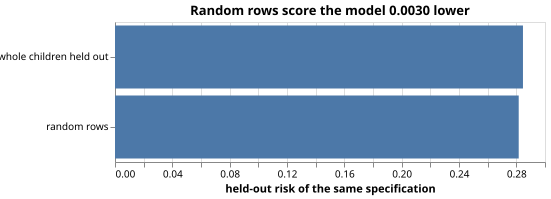

In [4]:
bars = alt.Chart(fold_rows).mark_bar().encode(
    y=alt.Y("fold design:N", title=None, sort="-x"),
    x=alt.X("held-out risk:Q", scale=alt.Scale(zero=False),
            title="held-out risk of the same specification"),
)
bars.properties(
    title=f"Random rows score the model {grouped_risk - random_risk:.4f} lower",
    width=430, height=140,
)

## Random-row and child-grouped validation

The random-row score evaluates children whose other exams the fit has
already seen. The `brandom(child)` term fits one shrunken level per
child, so a held-out exam of a partially seen child is partly predicted
by itself. The grouped score estimates prediction error for a child absent from fitting,
matching the intended screening task. The fold design is fixed before fitting
so that this prediction task governs model choice.


In [5]:
counts = fit.selection_counts(output="polars")

child_share = float(counts.filter(pl.col("column") == "child")["share"][0])
xero_row = counts.filter(pl.col("column") == "xero")
xero_updates = int(xero_row["updates"][0]) if xero_row.height else 0
xero_dropped = any("xero" in term for term, _ in rec.evidence["deselect"].dropped) \
    if "deselect" in rec.evidence else False
counts


learner,column,updates,share
str,str,i64,f64
"""child""","""child""",78,0.886364
"""round""","""round""",5,0.056818
"""age""","""age""",2,0.022727
"""age_first""","""age_first""",2,0.022727
"""height""","""height""",1,0.011364
"""cosine""","""cosine""",0,0.0
"""sine""","""sine""",0,0.0


## Selected updates and xerophthalmia

{eval}`f"{child_share:.0%}"` of the {eval}`step_count` updates went to the child effects,
so the fitted prediction relies heavily on child-specific levels. The fold
comparison measures performance on children absent from fitting.
Xerophthalmia received
{eval}`xero_updates` of them: {eval}`"autospec had already dropped it for a share of the risk reduction under 1%, so it is not in the fitted specification" if xero_dropped else "it stayed in the specification without being selected"`.
Xerophthalmia occurs at only 55 of 1200 exams, and its predictive information
can overlap the child effects. Its update count therefore cannot establish the
presence, absence or size of a causal effect. Its adjusted association is estimated separately in
"Declared treatment and causal-analysis functions".

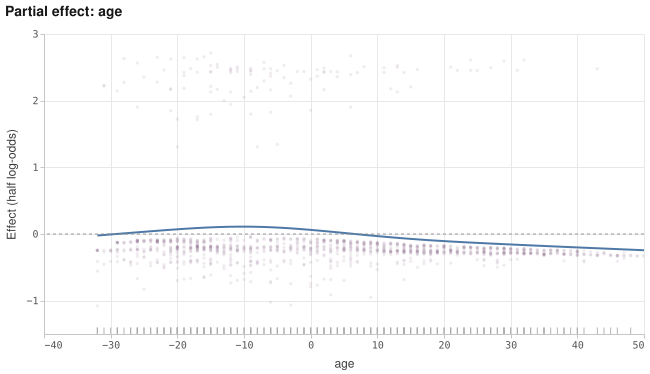

In [6]:
mb.plot.plot_partial_effects(fit, which="age")


## The age effect on the log-odds scale

The fitted contribution of age falls across the observed range: younger
children carry higher risk, the pattern the cohort was assembled to
study, and the vertical scale says how much — a fraction of a log-odds
unit, and the shape comparisons for age differ by less than the replacement rule
can detect. The points are
the per-observation contributions plus the working residual; they show
the binary noise a held-out child brings with it.

In [7]:
rec_causal = autospec(kids, "infection", treatment="xero")

print("formula:", rec_causal.formula)
print()

finding = next(f for f in rec_causal.hygiene if f.kind == "treatment")
print(finding)
print()
print(rec_causal.priority[0])


formula: infection ~ bbs(log(child), df=4.0) + bbs(age, df=4.0) + bbs(age_first, df=4.0) + brandom(cosine, df=4.0) + brandom(sine, df=4.0) + bols(female) + bbs(height, df=4.0) + bols(stunted) + bbs(round, df=4.0) + bols(season)

xero: declared as treatment, not as a predictor -- left out of the predictive specification. Predictive association is not an identification argument: for the effect of a treatment, use `mboostrs.causal` (`CausalSpec`, `aipw`, `negative_control`) rather than this fit

treatment: xero is declared as the treatment, so this recommendation leaves it out and measures no effect of it. Predictive association is not an identification argument: for the effect, use `mboostrs.causal` (`CausalSpec`, `aipw`, `negative_control`)


## Declared treatment and causal-analysis functions

Declaring xerophthalmia as the treatment removes it from the automatic
prediction specification and directs the analyst to three functions. `CausalSpec`
records the treatment, outcome, adjustment covariates and timing. `aipw`
estimates the effect by augmented inverse-probability weighting, which combines
an outcome model and a model for the probability of treatment and remains
consistent when either model is correct. `negative_control` checks the analysis
against an outcome or exposure that the treatment cannot affect. The code defines
an adjustment set and estimates an adjusted infection-risk difference. A causal
interpretation additionally requires the identifying assumptions stated in
"Adjusted risk difference and identifying assumptions".

In [8]:
from mboostrs.causal import CausalSpec, aipw

spec = CausalSpec(
    treatment="xero", outcome="infection",
    covariates=("age", "female", "stunted", "height", "season"),
    outcome_type="binary",
    time_zero="the quarterly exam",
    follow_up="infection status at the same exam",
    adjustment_rationale="age, season, sex and nutritional status are the "
    "recorded determinants of both vitamin A status and respiratory "
    "infection; prior illness is not recorded, so reverse causation "
    "remains possible and the estimate is an adjusted association",
)

estimate = aipw(kids, spec, folds=5, seed=0, mstop=600)
print(estimate)


AIPWResult(ate=0.0544113, se=0.045541440511234786, interval='available', n=1200, repeats=1)


## Adjusted risk difference and identifying assumptions

The adjusted risk difference is 0.054 (5.4 percentage points) with a standard
error of 0.046 on 55 exposed exams; the approximate 95% interval,
0.054 ± 1.96 × 0.046, runs from −0.035 to 0.144 and includes zero. The estimate
demonstrates the workflow and makes no new epidemiological claim; the published
analyses of this cohort report elevated infection risk among xerophthalmic
children. The estimate rests on the assumptions the spec carries. Consistency:
the observed outcome of an exam equals the outcome under the exposure the child
actually had. Conditional exchangeability: given the measured covariates, exposure
is independent of the outcomes the child would have under either exposure, so no
unmeasured confounding remains. Positivity: every covariate pattern has a nonzero
probability of both exposure levels. No interference: one child's exposure does
not affect another child's outcome. The weakest is exchangeability, for a reason
the spec itself records: prior illness is unmeasured, and infection can lower
vitamin A status, so reverse causation cannot be ruled out and the number is an
adjusted association.

In [9]:
sensitivity = mb.confounding_sensitivity(
    estimate,
    outcome_effects=(0.02, 0.05, 0.10),
    imbalances=(0.1, 0.2, 0.3),
)
sensitivity


outcome_effect,imbalance,assumed_bias,adjusted_estimate,changes_sign,lower,upper,interval_includes_zero
f64,f64,f64,f64,bool,f64,f64,bool
0.02,0.1,0.002,0.052411,false,-0.036848,0.141671,true
0.02,0.2,0.004,0.050411,false,-0.038848,0.139671,true
0.02,0.3,0.006,0.048411,false,-0.040848,0.137671,true
0.05,0.1,0.005,0.049411,false,-0.039848,0.138671,true
0.05,0.2,0.01,0.044411,false,-0.044848,0.133671,true
0.05,0.3,0.015,0.039411,false,-0.049848,0.128671,true
0.1,0.1,0.01,0.044411,false,-0.044848,0.133671,true
0.1,0.2,0.02,0.034411,false,-0.054848,0.123671,true
0.1,0.3,0.03,0.024411,false,-0.064848,0.113671,true


## Confounding sensitivity and interpretation limits

The sensitivity grid quantifies one possible unmeasured-confounding scenario: an unmeasured binary
confounder 20 percentage points more prevalent among xerophthalmic
children and worth 5 points of infection risk would lower the estimate
from 0.054 to 0.044.

The grouped folds evaluate prediction for new children. Update counts show
how much the fitted path uses child-specific effects, while the adjusted risk
difference addresses xerophthalmia under the stated assumptions. The shape
comparisons do not resolve an advantage among the tested alternatives, and the
interaction leads have not been tested on held-out folds. Treating the seasonal coordinates as measurements
remains an analyst choice; prior illness and other unrecorded confounders
limit the interpretation of the risk difference.